# California Home Price Prediction
## Week 4: Linear Regression Baseline

This notebook trains the first model, selects a training window with time-based validation, and evaluates the final model on April 2026.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "california_sfr_cleaned_week3.csv"
RANDOM_STATE = 42

## 1. Load the Week 3 data

Use the cleaned data and the chronological split created in Week 3.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["CloseDate"])

numeric_features = [
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
    "LotSizeSquareFeet", "YearBuilt"
]
categorical_features = ["City", "CountyOrParish"]
features = numeric_features + categorical_features
target = "ClosePrice"

split_summary = df.groupby("DataSplit").agg(
    rows=(target, "size"),
    first_month=("SourceMonth", "min"),
    last_month=("SourceMonth", "max"),
    median_price=(target, "median"),
)
display(split_summary)
print(f"Total rows: {len(df):,}")

,rows,first_month,last_month,median_price
DataSplit,,,,
test,12031,202604,202604,"921,000.000"
train,129716,202504,202603,"886,550.000"


Total rows: 141,747


## 2. Build the baseline pipeline

The pipeline standardizes numeric features, one-hot encodes city and county, and fits Linear Regression. Unknown locations can be handled safely.

In [3]:
def make_model():
    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ])

## 3. Select the training window

Use March 2026 as a temporary validation month. April 2026 remains untouched. Compare each window using validation R² and choose the best result.

In [4]:
development = df[df["SourceMonth"] < 202604].copy()
validation = development[development["SourceMonth"] == 202603].copy()
history = development[development["SourceMonth"] < 202603].copy()
available_months = sorted(history["SourceMonth"].unique())

validation_results = []
for window in [3, 6, 9, 11]:
    selected_months = available_months[-window:]
    training = history[history["SourceMonth"].isin(selected_months)]

    candidate = make_model()
    candidate.fit(training[features], training[target])
    predictions = candidate.predict(validation[features])

    validation_results.append({
        "training_months": window,
        "training_rows": len(training),
        "validation_r2": r2_score(validation[target], predictions),
        "validation_mae": mean_absolute_error(validation[target], predictions),
    })

validation_results = pd.DataFrame(validation_results)
display(validation_results)

best_window = int(validation_results.loc[validation_results["validation_r2"].idxmax(), "training_months"])
print(f"Best validation window: {best_window} months")

,training_months,training_rows,validation_r2,validation_mae
0,3,26475,0.026,"478,019.302"
1,6,59665,0.024,"507,775.593"
2,9,94910,0.029,"498,342.281"
3,11,118545,0.035,"493,622.757"


Best validation window: 11 months


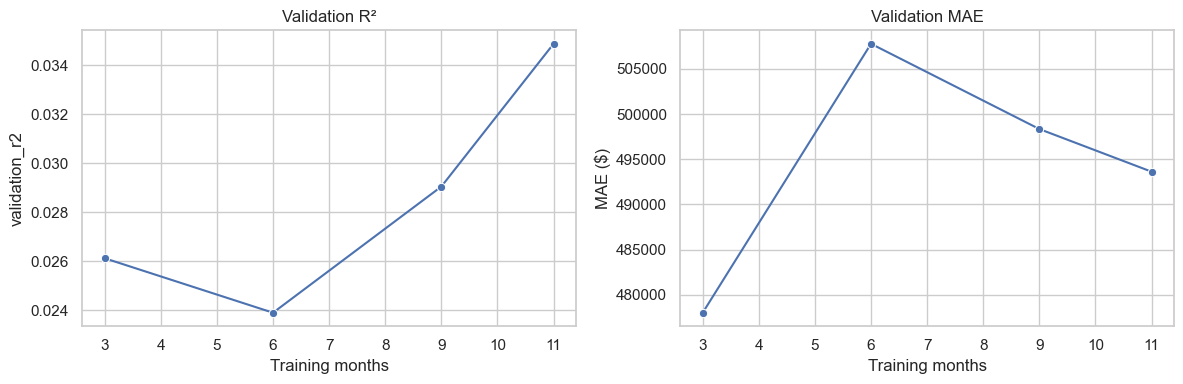

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=validation_results, x="training_months", y="validation_r2", marker="o", ax=axes[0])
axes[0].set_title("Validation R²")
axes[0].set_xlabel("Training months")
sns.lineplot(data=validation_results, x="training_months", y="validation_mae", marker="o", ax=axes[1])
axes[1].set_title("Validation MAE")
axes[1].set_xlabel("Training months")
axes[1].set_ylabel("MAE ($)")
plt.tight_layout()
plt.show()

## 4. Train the final baseline

The best validation result uses all 11 months available before March. After that decision, include March and train on the full 12-month Week 3 training set. Evaluate only once on April 2026.

In [6]:
train = df[df["DataSplit"] == "train"].copy()
test = df[df["DataSplit"] == "test"].copy()

baseline_model = make_model()
baseline_model.fit(train[features], train[target])
test_predictions = baseline_model.predict(test[features])

assert set(train["ListingKey"]).isdisjoint(set(test["ListingKey"]))
print(f"Final training rows: {len(train):,}")
print(f"Final test rows: {len(test):,}")

Final training rows: 129,716
Final test rows: 12,031


## 5. Evaluate the model

R² is the required Week 4 metric. MAE and RMSE make the error size easier to understand. A median-price prediction is included as a simple reference.

In [7]:
overall_r2 = r2_score(test[target], test_predictions)
overall_mae = mean_absolute_error(test[target], test_predictions)
overall_rmse = mean_squared_error(test[target], test_predictions) ** 0.5

median_predictions = np.repeat(train[target].median(), len(test))
median_mae = mean_absolute_error(test[target], median_predictions)

metrics = pd.DataFrame({
    "metric": ["R²", "MAE", "RMSE", "Median baseline MAE"],
    "value": [overall_r2, overall_mae, overall_rmse, median_mae],
})
display(metrics)
print(f"Linear Regression reduces MAE by {(1 - overall_mae / median_mae) * 100:.1f}% versus the median baseline.")

,metric,value
0,R²,0.009
1,MAE,"627,407.923"
2,RMSE,"11,709,072.297"
3,Median baseline MAE,"882,794.263"


Linear Regression reduces MAE by 28.9% versus the median baseline.


## 6. Understand the result

The full test set contains a few extremely high prices. Report the official full-set R², then inspect the central 98% only as a diagnostic—not as a replacement score.

In [8]:
lower, upper = test[target].quantile([0.01, 0.99])
typical_mask = test[target].between(lower, upper)
typical_actual = test.loc[typical_mask, target]
typical_predictions = test_predictions[typical_mask]

diagnostic = pd.DataFrame({
    "group": ["All test properties", "Central 98% price range"],
    "rows": [len(test), int(typical_mask.sum())],
    "r2": [overall_r2, r2_score(typical_actual, typical_predictions)],
    "mae": [overall_mae, mean_absolute_error(typical_actual, typical_predictions)],
})
display(diagnostic)
print(f"Central price range: ${lower:,.0f} to ${upper:,.0f}")
print(f"Actual test maximum: ${test[target].max():,.0f}")

,group,rows,r2,mae
0,All test properties,12031,0.009,"627,407.923"
1,Central 98% price range,11798,0.502,"395,596.025"


Central price range: $235,000 to $6,767,500
Actual test maximum: $796,000,000


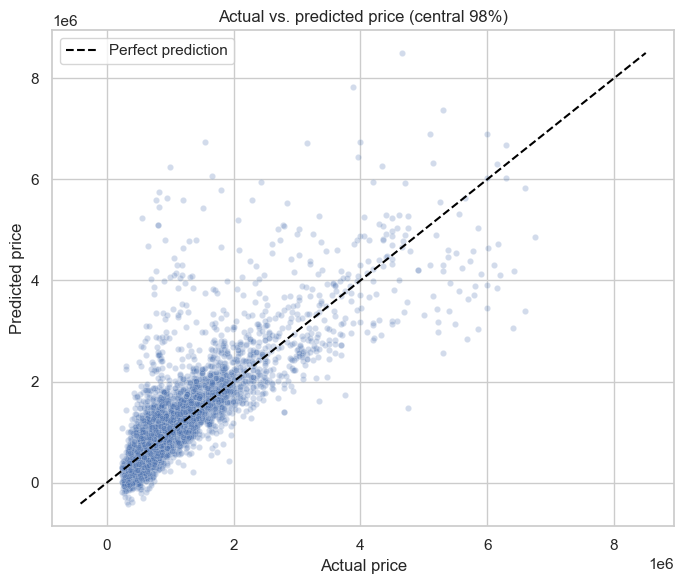

In [9]:
plot_data = pd.DataFrame({
    "Actual price": typical_actual,
    "Predicted price": typical_predictions,
})
plot_data = plot_data.sample(n=min(4000, len(plot_data)), random_state=RANDOM_STATE)

plt.figure(figsize=(7, 6))
sns.scatterplot(data=plot_data, x="Actual price", y="Predicted price", alpha=0.25, s=20)
line_min = min(plot_data.min())
line_max = max(plot_data.max())
plt.plot([line_min, line_max], [line_min, line_max], "--", color="black", label="Perfect prediction")
plt.title("Actual vs. predicted price (central 98%)")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

- The 11-month window performed best on March validation, so the final model used all 12 available training months.
- Final test R²: **0.009** on all April 2026 properties.
- Final test MAE: approximately **$627,408**.
- Linear Regression improved MAE by about **29%** compared with always predicting the training median.
- For the central 98% of test prices, diagnostic R² was **0.502**.
- Extreme prices strongly affect overall R² and RMSE, and some predictions are negative.

The baseline captures a useful general pattern for common properties, but it is not strong enough for final use. Week 5 should compare Decision Tree and Random Forest models, while keeping the same chronological test set.